# Human Activity Recognition with Smartphones

**Hands-on Machine Learning**

**Group members:** PETRIT Frédéric-Henri, Celin--Davanture Guilian, JIN Céline

## 1. Introduction

Human Activity Recognition (HAR) consists of automatically identifying physical activities performed by individuals using data collected from sensors.

Smartphones contain sensors like accelerometers and gyroscopes, which capture human movements and changes in orientations in time series, providing input data to classify human activities. In our case the time series were tabulated with measurements made on each time window.

The objective of this project is to develop and evaluate machine learning models capable of classifying six human activities:

- Walking
- Walking Upstairs
- Walking Downstairs
- Sitting
- Standing
- Laying

We use the *Human Activity Recognition Using Smartphones* dataset, which contains 10,299 observations and 561 extracted features from smartphone sensor measurements.

The dataset was collected from 30 volunteers performing six different activities.

**Source:** https://www.kaggle.com/uciml/human-activity-recognition-with-smartphones

### Research Question

How do different dimensionality reduction techniques affect the performance of machine learning models for smartphone-based human activity recognition?

### Evaluated Models

We are measuring and comparing the performance of 3 classic classification machine learning models for this task, and we study the impact of 2 dimensionality reduction techniques on them.

**Classification**:
- logistic regression
- support vector machine
- random forest

**Dimensionality reduction**:
- principal component analysis
- feature selection

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# this makes the plots from matplotlib appear directly below the cells that generate it
%matplotlib inline

In [2]:
train_df = pd.read_csv("train.csv")
test_df = pd.read_csv("test.csv")

print("Training dataset:", train_df.shape)
print("Testing dataset:", test_df.shape)

Training dataset: (7352, 563)
Testing dataset: (2947, 563)


In [3]:
train_df.head()

,tBodyAcc-mean()-X,tBodyAcc-mean()-Y,tBodyAcc-mean()-Z,tBodyAcc-std()-X,tBodyAcc-std()-Y,tBodyAcc-std()-Z,tBodyAcc-mad()-X,tBodyAcc-mad()-Y,tBodyAcc-mad()-Z,tBodyAcc-max()-X,...,fBodyBodyGyroJerkMag-kurtosis(),"angle(tBodyAccMean,gravity)","angle(tBodyAccJerkMean),gravityMean)","angle(tBodyGyroMean,gravityMean)","angle(tBodyGyroJerkMean,gravityMean)","angle(X,gravityMean)","angle(Y,gravityMean)","angle(Z,gravityMean)",subject,Activity
0,0.288585,-0.020294,-0.132905,-0.995279,-0.983111,-0.913526,-0.995112,-0.983185,-0.923527,-0.934724,...,-0.710304,-0.112754,0.030400,-0.464761,-0.018446,-0.841247,0.179941,-0.058627,1,STANDING
1,0.278419,-0.016411,-0.123520,-0.998245,-0.975300,-0.960322,-0.998807,-0.974914,-0.957686,-0.943068,...,-0.861499,0.053477,-0.007435,-0.732626,0.703511,-0.844788,0.180289,-0.054317,1,STANDING
2,0.279653,-0.019467,-0.113462,-0.995380,-0.967187,-0.978944,-0.996520,-0.963668,-0.977469,-0.938692,...,-0.760104,-0.118559,0.177899,0.100699,0.808529,-0.848933,0.180637,-0.049118,1,STANDING
3,0.279174,-0.026201,-0.123283,-0.996091,-0.983403,-0.990675,-0.997099,-0.982750,-0.989302,-0.938692,...,-0.482845,-0.036788,-0.012892,0.640011,-0.485366,-0.848649,0.181935,-0.047663,1,STANDING
4,0.276629,-0.016570,-0.115362,-0.998139,-0.980817,-0.990482,-0.998321,-0.979672,-0.990441,-0.942469,...,-0.699205,0.123320,0.122542,0.693578,-0.615971,-0.847865,0.185151,-0.043892,1,STANDING


## 2. Data Analysis and Preprocessing

Several preprocessing steps are needed depending on the model choice.
We explore the dataset to better understand its structure and apply the needed modifications.
- assess data structure & quality, process duplicates or missing values
- ensure class distribution is balanced
- reduce the range of the features mean and variance (standardization)
- detect high correlation between features

We apply the appropriate modifications depending on the results, including a PCA to later compare the model's performance with and without this dimensionality reduction.

In [4]:
# general information
train_df.info()

# missing values
print("Missing values:", train_df.isnull().sum().sum())

# duplicated rows
print("Duplicated rows:", train_df.duplicated().sum())

<class 'pandas.DataFrame'>
RangeIndex: 7352 entries, 0 to 7351
Columns: 563 entries, tBodyAcc-mean()-X to Activity
dtypes: float64(561), int64(1), str(1)
memory usage: 31.6 MB
Missing values: 0
Duplicated rows: 0


There are **7 352** observations and **563** columns.

**561** numerical features, 1 **subject identifier** `subject`, 1 **target variable** `Activity`.

There are no missing values or duplicated rows hence no duplicate removal is needed.

In [5]:
# Separate features and target
X_train = train_df.drop(columns=["Activity", "subject"])
y_train = train_df["Activity"]

X_test = test_df.drop(columns=["Activity", "subject"])
y_test = test_df["Activity"]


# Identify constant features
constant_features = X_train.columns[X_train.nunique() == 1]

print("Number of features:", X_train.shape[1])
print("Number of constant features:", len(constant_features))
print("Constant features:", constant_features.tolist())

Number of features: 561
Number of constant features: 0
Constant features: []


We also check for constant features. There are none.

### 2.1 Class Distribution

The dataset contains six activities: LAYING, SITTING, STANDING, WALKING, WALKING_UPSTAIRS, and WALKING_DOWNSTAIRS.

Let's count how many observations exist for each of these activities.

Activity
LAYING                1407
STANDING              1374
SITTING               1286
WALKING               1226
WALKING_UPSTAIRS      1073
WALKING_DOWNSTAIRS     986
Name: count, dtype: int64


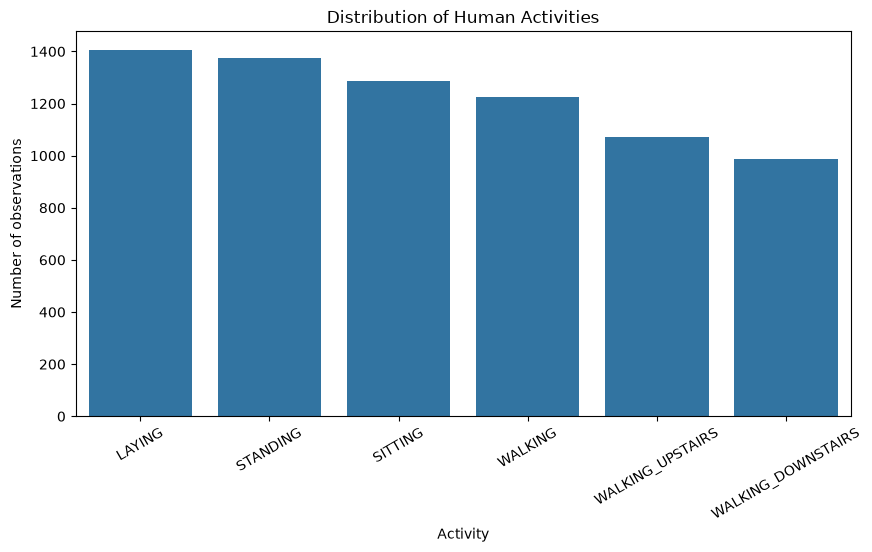

In [6]:
print(train_df["Activity"].value_counts())

# figsize in inches
plt.figure(figsize=(10, 5))

sns.countplot(
    data=train_df,
    x="Activity",
    order=train_df["Activity"].value_counts().index # display bars in decreasing count order, extracting category names
)

plt.title("Distribution of Human Activities")
plt.xlabel("Activity")
plt.ylabel("Number of observations")
plt.xticks(rotation=30)
plt.show()

The classes are approximately balanced (13.4% to 19.1%).

LAYING is the most frequent activity representing **19.1%** of the observations, while WALKING_DOWNSTAIRS is the least frequent representing **13.4%** of them.

As the imbalance is really moderate, we do not apply resampling techniques.

In addition to using accuracy to evaluate our models, we will also use a **macro-averaged F1-score**.

This gives each class equal weight when computing the average F1-score per class.

### 2.2 Descriptive Statistics

We are just computing simple metrics on each feature, including the mean and standard deviation to normalize them.

This is important especially for SVMs and distance sensitive kernels, also for logistic regression, and usually not needed for random forests.

This is also really important for PCA because a large variance feature can then dominate in the extracted components. PCA maximizes retained variance.

We can see small differences between feature means and variance despite these approximately being contained in a reasonable range.

Taking this into account, we are using `StandardScaler` in our preprocessing.

In [7]:
# Display summary statistics for the first 15 features
X_train.describe().T.head(15)

,count,mean,std,min,25%,50%,75%,max
tBodyAcc-mean()-X,7352.0,0.274488,0.070261,-1.000000,0.262975,0.277193,0.288461,1.000000
tBodyAcc-mean()-Y,7352.0,-0.017695,0.040811,-1.000000,-0.024863,-0.017219,-0.010783,1.000000
tBodyAcc-mean()-Z,7352.0,-0.109141,0.056635,-1.000000,-0.120993,-0.108676,-0.097794,1.000000
tBodyAcc-std()-X,7352.0,-0.605438,0.448734,-1.000000,-0.992754,-0.946196,-0.242813,1.000000
tBodyAcc-std()-Y,7352.0,-0.510938,0.502645,-0.999873,-0.978129,-0.851897,-0.034231,0.916238
tBodyAcc-std()-Z,7352.0,-0.604754,0.418687,-1.000000,-0.980233,-0.859365,-0.262415,1.000000
tBodyAcc-mad()-X,7352.0,-0.630512,0.424073,-1.000000,-0.993591,-0.950709,-0.292680,1.000000
tBodyAcc-mad()-Y,7352.0,-0.526907,0.485942,-1.000000,-0.978162,-0.857328,-0.066701,0.967664
tBodyAcc-mad()-Z,7352.0,-0.606150,0.414122,-1.000000,-0.980251,-0.857143,-0.265671,1.000000
tBodyAcc-max()-X,7352.0,-0.468604,0.544547,-1.000000,-0.936219,-0.881637,-0.017129,1.000000


In [8]:
scaler = StandardScaler()

# standardization, fit on training set, just transform the test set
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

### 2.3 Highly correlated features

We compute a Pearson correlation matrix on the training dataset to identify highly correlated and therefore redundant pairs of features.

**2 281** feature pairs had an absolute correlation greater than **0.95**.

There are **561** features so **561 choose 2** = **157 080** pairs. This means that **1.45%** of our feature pairs are highly correlated.

This result motivates the evaluation of feature selection and principal component analysis to assess how well dimensionality can be reduced while maintaining classification performance or even increase accuracy.

In [9]:
# compute correlations between features
corr_matrix = X_train.corr().abs()

# keep only unique feature pairs
upper_triangle = corr_matrix.where(
    np.triu(np.ones(corr_matrix.shape), k=1).astype(bool)
)

# count highly correlated feature pairs
high_corr_pairs = (upper_triangle > 0.95).sum().sum()

print("Highly correlated feature pairs:", high_corr_pairs)

Highly correlated feature pairs: 2281


### Example with tBodyAcc-std()-X to show high dependence

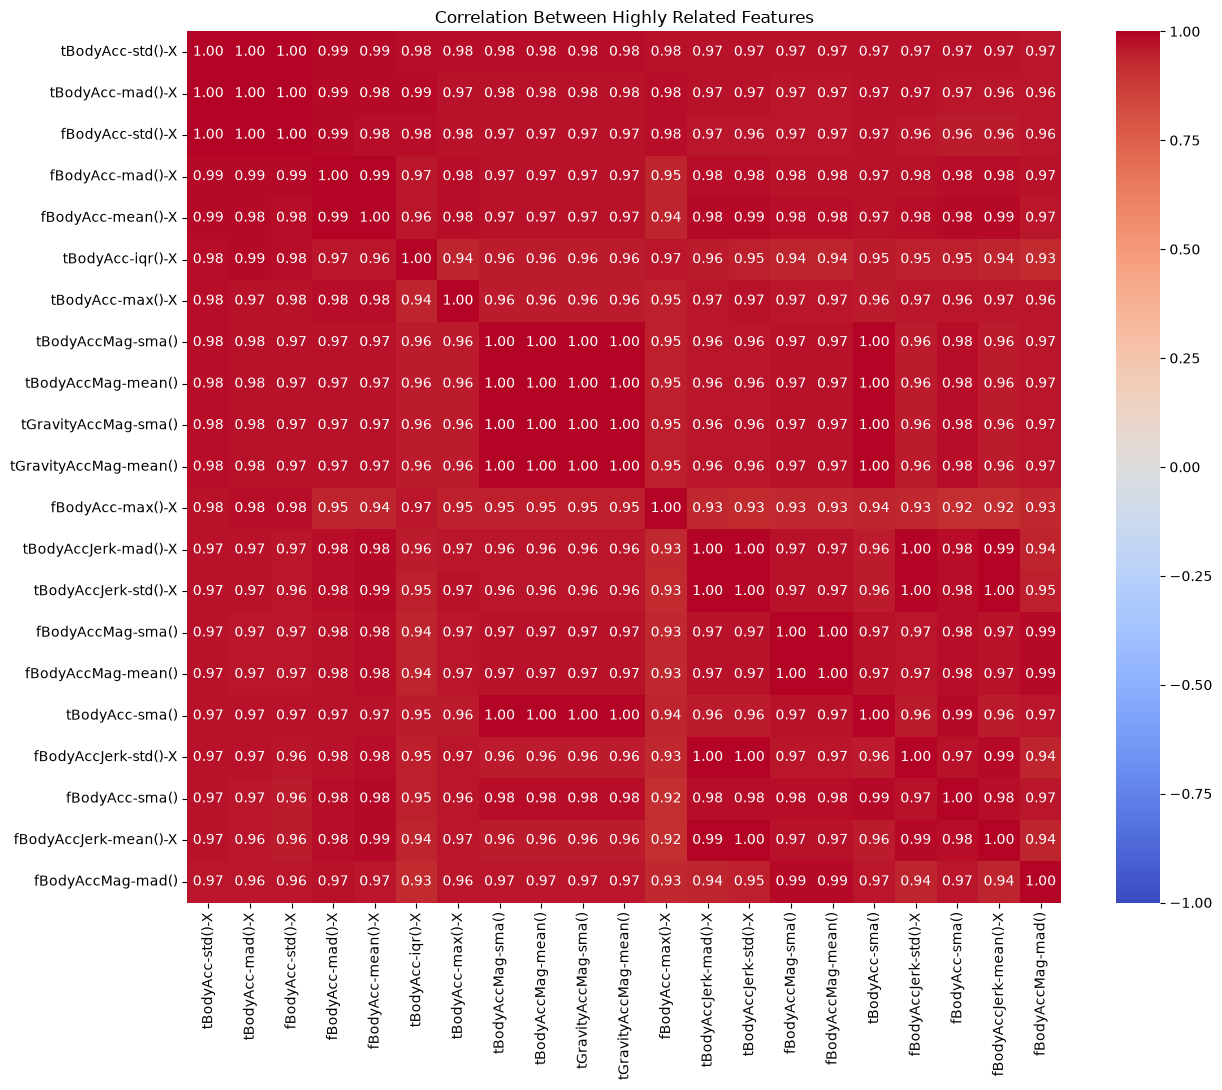

In [10]:
target_feature = "tBodyAcc-std()-X"

correlations = (
    X_train.corr()[target_feature]
    .drop(target_feature)
    .abs()
    .sort_values(ascending=False)
)

top_features = correlations.head(20).index

selected_columns = [target_feature] + list(top_features)

plt.figure(figsize=(13, 11))

sns.heatmap(
    X_train[selected_columns].corr(),
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0
)

plt.title("Correlation Between Highly Related Features")
plt.tight_layout()
plt.show()

### 2.4 PCA reasonable minimum number of components

We apply PCA to the standardized training features to know how much of the variance can be retained using fewer dimensions.

We compute the minimum number of principal components required to preserve at least 95% of the total variance.

Further classification experiments are needed to assess the impact of the PCA on using subsequent models.

Here we just need to determine the most efficient PCA that will not be too aggressive.

Original features: 561
Components for 95% variance: 102


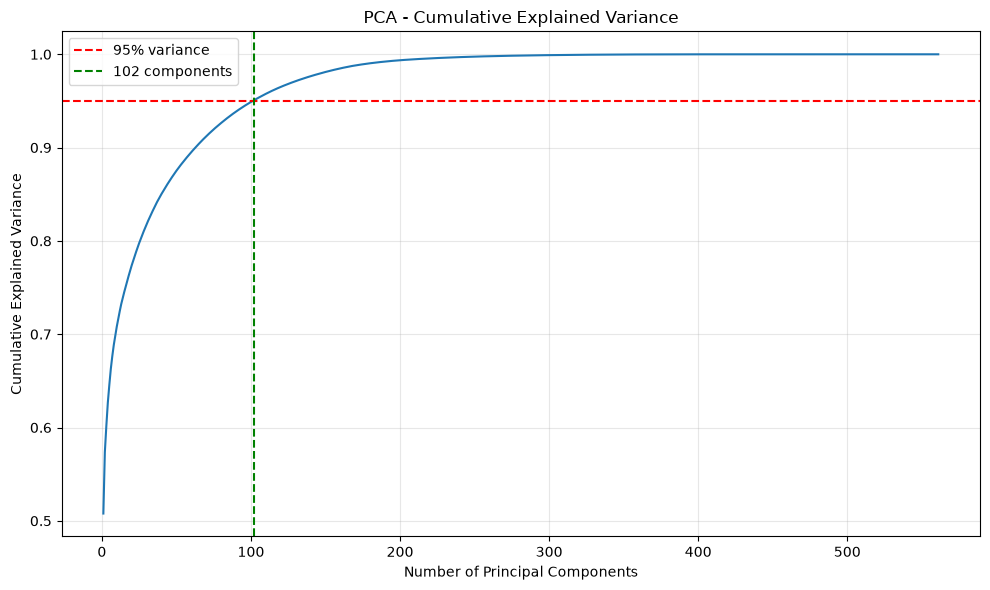

In [11]:
# fit PCA on standardized features
pca = PCA()
pca.fit(X_train_scaled)

# compute cumulative explained variance
cumulative_variance = np.cumsum(pca.explained_variance_ratio_)

# Find the number of components explaining 95% of the variance
n_components_95 = np.searchsorted(cumulative_variance, 0.95) + 1

print(f"Original features: {X_train.shape[1]}")
print(f"Components for 95% variance: {n_components_95}")

# Plot cumulative explained variance
plt.figure(figsize=(10, 6))

plt.plot(
    range(1, len(cumulative_variance) + 1),
    cumulative_variance
)

plt.axhline(0.95, color="red", linestyle="--", label="95% variance")
plt.axvline(
    n_components_95,
    color="green",
    linestyle="--",
    label=f"{n_components_95} components"
)

plt.xlabel("Number of Principal Components")
plt.ylabel("Cumulative Explained Variance")
plt.title("PCA - Cumulative Explained Variance")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

The results show that 102 (out of 561) principal components are sufficient to explain at least 95% of the total variance.

We reduced the dimension count by 81.8%.

The explained variance curve increases rapidly for the first components before slowing down: much of the variance can be retained using a small number of components.

PCA retaining much of the variance does not guarantee a close to equally accurate classification.

We are evaluating this phenomenon, by comparing models using all 561 original features with models using the 102 PCA components.

### 2.5 PCA Data Transformation

We apply PCA to the standardized training data, retaining at least 95% of the total variance.

Same for test set without re fitting the PCA obviously.

The resulting datasets will be used to evaluate classification models and compare their performance against models trained on the original features.

In [12]:
# Apply PCA to retain at least 95% of the variance
pca_95 = PCA(n_components=0.95)

X_train_pca = pca_95.fit_transform(X_train_scaled)
X_test_pca = pca_95.transform(X_test_scaled)

# Compare original and reduced dimensions
print(f"Original training shape: {X_train_scaled.shape}")
print(f"Original testing shape:  {X_test_scaled.shape}")
print(f"PCA training shape:      {X_train_pca.shape}")
print(f"PCA testing shape:       {X_test_pca.shape}")

Original training shape: (7352, 561)
Original testing shape:  (2947, 561)
PCA training shape:      (7352, 102)
PCA testing shape:       (2947, 102)


## 3. Model Training

### 3.1 Logistic Regression Baseline

We use Logistic Regression as our baseline classification model, trained on the original 561 features.

To evaluate its ability to generalize to unseen individuals, we use subject-aware cross-validation, ensuring that observations from the same participant are not shared between training and validation sets. 

We avoid what is called subject or participant leakage. If the cross validation is not participant aware the model may benefit from person-specific learned patterns and still not generalize well to new people.

In [13]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GroupKFold, cross_validate
from sklearn.pipeline import Pipeline

# identify participants 
groups = train_df["subject"]

# 5 folds separating the participants
cv = GroupKFold(n_splits=5)

# log reg pipeline
lr_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(max_iter=2000))
])

# evaluate the model using cross-validation
lr_scores = cross_validate(
    lr_pipeline,
    X_train,
    y_train,
    groups=groups,
    cv=cv,
    scoring=["accuracy", "f1_macro"],
    n_jobs=-1
)

# Display evaluation results
print(f"Mean Accuracy: {lr_scores['test_accuracy'].mean():.4f}")
print(f"Std Accuracy:  {lr_scores['test_accuracy'].std():.4f}")
print(f"Mean F1-macro: {lr_scores['test_f1_macro'].mean():.4f}")

Mean Accuracy: 0.9345
Std Accuracy:  0.0391
Mean F1-macro: 0.9335


### 3.2 Logistic Regression with PCA

We now evaluate the impact of PCA on Logistic Regression performance.

PCA is applied after standardization to reduce dimensionality while retaining at least 95% of the variance.

We use the same subject-aware cross-validation strategy as the baseline to ensure a fair comparison. Both standardization and PCA are fitted within each training fold to avoid data leakage.

The results will be compared with the baseline model trained on all 561 features.

In [14]:
# Pipeline: StandardScaler + PCA + Logistic Regression
lr_pca_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("pca", PCA(n_components=0.95)),
    ("classifier", LogisticRegression(max_iter=2000))
])

# Evaluate using subject-aware cross-validation
lr_pca_scores = cross_validate(
    lr_pca_pipeline,
    X_train,
    y_train,
    groups=groups,
    cv=cv,
    scoring=["accuracy", "f1_macro"],
    n_jobs=-1
)

# Display results
print(f"Mean Accuracy: {lr_pca_scores['test_accuracy'].mean():.4f}")
print(f"Std Accuracy:  {lr_pca_scores['test_accuracy'].std():.4f}")
print(f"Mean F1-macro: {lr_pca_scores['test_f1_macro'].mean():.4f}")

Mean Accuracy: 0.9195
Std Accuracy:  0.0428
Mean F1-macro: 0.9180


Logistic Regression achieved a mean accuracy of 91.94% and a macro F1-score of 91.80% after applying PCA to retain at least 95% of the variance.

Compared with the baseline using all 561 features, accuracy decreased by 1.48 percentage points, while macro F1-score decreased by 1.50 points.

These results suggest that PCA can reduce dimensionality while maintaining high classification performance.

However, the original feature representation achieved better predictive performance.

### 3.3 SVM Baseline

We use a Support Vector Machine (SVM) with an RBF kernel as our second baseline model, trained on all 561 original features.

The model is evaluated using the same subject-aware cross-validation strategy and performance metrics as Logistic Regression to ensure a fair comparison.

In [15]:
from sklearn.svm import SVC

# Create the SVM pipeline
svm_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", SVC(
        kernel="rbf",
        C=1.0,
        gamma="scale"
    ))
])

# Evaluate using subject-aware cross-validation
svm_scores = cross_validate(
    svm_pipeline,
    X_train,
    y_train,
    groups=groups,
    cv=cv,
    scoring=["accuracy", "f1_macro"],
    n_jobs=-1
)

# Display results
print(f"Mean Accuracy: {svm_scores['test_accuracy'].mean():.4f}")
print(f"Std Accuracy:  {svm_scores['test_accuracy'].std():.4f}")
print(f"Mean F1-macro: {svm_scores['test_f1_macro'].mean():.4f}")

Mean Accuracy: 0.9233
Std Accuracy:  0.0407
Mean F1-macro: 0.9220


### 3.4 SVM with PCA

We evaluate the impact of PCA on SVM classification performance.

PCA is applied after standardization to retain at least 95% of the variance. The SVM uses the same RBF kernel and hyperparameters as the baseline model.

We use the same subject-aware cross-validation strategy to compare performance with and without dimensionality reduction.

In [16]:
# Create the SVM pipeline with PCA
svm_pca_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("pca", PCA(n_components=0.95)),
    ("classifier", SVC(
        kernel="rbf",
        C=1.0,
        gamma="scale"
    ))
])

# Evaluate using subject-aware cross-validation
svm_pca_scores = cross_validate(
    svm_pca_pipeline,
    X_train,
    y_train,
    groups=groups,
    cv=cv,
    scoring=["accuracy", "f1_macro"],
    n_jobs=-1
)

# Display results
print(f"Mean Accuracy: {svm_pca_scores['test_accuracy'].mean():.4f}")
print(f"Std Accuracy:  {svm_pca_scores['test_accuracy'].std():.4f}")
print(f"Mean F1-macro: {svm_pca_scores['test_f1_macro'].mean():.4f}")

Mean Accuracy: 0.9091
Std Accuracy:  0.0441
Mean F1-macro: 0.9091


### 3.5 Results Logistic regression and SVM

In [17]:
comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Logistic Regression",
        "SVM",
        "SVM"
    ],
    "Approach": [
        "Original Features",
        "PCA (95%)",
        "Original Features",
        "PCA (95%)"
    ],
    "Mean Accuracy": [
        lr_scores["test_accuracy"].mean(),
        lr_pca_scores["test_accuracy"].mean(),
        svm_scores["test_accuracy"].mean(),
        svm_pca_scores["test_accuracy"].mean()
    ],
    "Mean F1-macro": [
        lr_scores["test_f1_macro"].mean(),
        lr_pca_scores["test_f1_macro"].mean(),
        svm_scores["test_f1_macro"].mean(),
        svm_pca_scores["test_f1_macro"].mean()
    ]
})

display(comparison.round(4))

,Model,Approach,Mean Accuracy,Mean F1-macro
0,Logistic Regression,Original Features,0.9345,0.9335
1,Logistic Regression,PCA (95%),0.9195,0.9180
2,SVM,Original Features,0.9233,0.9220
3,SVM,PCA (95%),0.9091,0.9091


### 3.6 Comparison of Logistic Regression and SVM

We compared Logistic Regression and SVM with an RBF kernel using five-fold subject-aware cross-validation.

Logistic Regression achieved the highest mean accuracy (93.42%) and macro F1-score (93.30%), compared with 92.33% accuracy and 92.20% macro F1-score for SVM.

Applying PCA to retain at least 95% of the variance slightly reduced classification performance for both models. Mean accuracy decreased by 1.48 percentage points for Logistic Regression and 1.42 points for SVM.

These results suggest that the original features provide better classification performance under the current experimental settings. However, PCA substantially reduces dimensionality while maintaining accuracy above 90%.

The results highlight a trade-off between dimensionality reduction and predictive performance. We will next investigate whether feature selection can achieve a better balance by retaining a subset of the original features.

### 3.7 Random Forest Baseline

We introduce Random Forest as a third classification model to compare different machine learning approaches.

Random Forest combines multiple decision trees to capture nonlinear relationships between features. Unlike Logistic Regression and SVM, it does not require feature standardization.

We evaluate the model using the same five-fold subject-aware cross-validation strategy and performance metrics to ensure a fair comparison.

In [18]:
from sklearn.ensemble import RandomForestClassifier

# Create the Random Forest pipeline
rf_pipeline = Pipeline([
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        n_jobs=-1
    ))
])

# Evaluate using subject-aware cross-validation
rf_scores = cross_validate(
    rf_pipeline,
    X_train,
    y_train,
    groups=groups,
    cv=cv,
    scoring=["accuracy", "f1_macro"],
    n_jobs=1
)

# Display results
print(f"Mean Accuracy: {rf_scores['test_accuracy'].mean():.4f}")
print(f"Std Accuracy:  {rf_scores['test_accuracy'].std():.4f}")
print(f"Mean F1-macro: {rf_scores['test_f1_macro'].mean():.4f}")

Mean Accuracy: 0.9175
Std Accuracy:  0.0443
Mean F1-macro: 0.9163


### 3.8 Random Forest with PCA

We evaluate the impact of PCA on Random Forest classification performance.

PCA is applied after standardization to retain at least 95% of the variance. We use the same Random Forest hyperparameters as the baseline model.

The model is evaluated using five-fold subject-aware cross-validation to determine whether dimensionality reduction affects its classification performance.

In [19]:
# Create the Random Forest pipeline with PCA
rf_pca_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("pca", PCA(n_components=0.95)),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        n_jobs=-1
    ))
])

# Evaluate using subject-aware cross-validation
rf_pca_scores = cross_validate(
    rf_pca_pipeline,
    X_train,
    y_train,
    groups=groups,
    cv=cv,
    scoring=["accuracy", "f1_macro"],
    n_jobs=1
)

# Display results
print(f"Mean Accuracy: {rf_pca_scores['test_accuracy'].mean():.4f}")
print(f"Std Accuracy:  {rf_pca_scores['test_accuracy'].std():.4f}")
print(f"Mean F1-macro: {rf_pca_scores['test_f1_macro'].mean():.4f}")

Mean Accuracy: 0.8513
Std Accuracy:  0.0519
Mean F1-macro: 0.8465


### Random Forest Results

Random Forest achieved a mean accuracy of 91.75% and a macro F1-score of 91.63% using the original 561 features.

After applying PCA to retain at least 95% of the variance, accuracy decreased to 85.19% and macro F1-score to 84.66%.

This reduction of 6.56 percentage points in accuracy is considerably larger than the decreases observed for Logistic Regression and SVM.

One possible explanation is that Random Forest relies on axis-aligned decision splits, which may become less effective when the original features are replaced by PCA components.

These results suggest that the impact of dimensionality reduction depends on the classification algorithm.

## 4. Feature Selection


We investigate whether selecting a subset of the original features can maintain classification performance while reducing dimensionality.

Unlike PCA, which creates new components, feature selection preserves the original features considered most relevant for activity classification.

We use SelectKBest with ANOVA F-scores to evaluate subsets of 50, 100, and 200 features. Feature selection is performed within each training fold to avoid data leakage.

### 4.1 Logistic Regression

In [20]:
from sklearn.feature_selection import SelectKBest, f_classif

# Number of features to evaluate
feature_counts = [50, 100, 200]

lr_fs_results = []

for k in feature_counts:
    pipeline = Pipeline([
        ("scaler", StandardScaler()),
        ("selector", SelectKBest(score_func=f_classif, k=k)),
        ("classifier", LogisticRegression(max_iter=2000))
    ])

    scores = cross_validate(
        pipeline,
        X_train,
        y_train,
        groups=groups,
        cv=cv,
        scoring=["accuracy", "f1_macro"],
        n_jobs=-1
    )

    lr_fs_results.append({
        "Features": k,
        "Mean Accuracy": scores["test_accuracy"].mean(),
        "Mean F1-macro": scores["test_f1_macro"].mean()
    })

lr_fs_df = pd.DataFrame(lr_fs_results)
display(lr_fs_df.round(4))

,Features,Mean Accuracy,Mean F1-macro
0,50,0.8707,0.8739
1,100,0.9102,0.9088
2,200,0.9240,0.9220


Feature selection was evaluated using 50, 100, and 200 features with Logistic Regression.

Classification performance improved as the number of selected features increased. The highest accuracy (92.42%) and macro F1-score (92.23%) were obtained with 200 features.

Compared with the baseline using all 561 features, this represents a dimensionality reduction of approximately 64.3%, with an accuracy decrease of only 1 percentage point.

These results suggest that many original features can be removed while maintaining relatively high classification performance.

However, further experiments are needed to compare feature selection and PCA at similar dimensionalities.

### 4.2 SVM with Feature Selection

We evaluate the impact of feature selection on SVM classification performance using an RBF kernel.

We apply SelectKBest with ANOVA F-scores to select 50, 100, and 200 features.

The same five-fold subject-aware cross-validation strategy is used to compare SVM performance with the original features and PCA.

In [21]:
# Evaluate SVM with different numbers of selected features
svm_fs_results = []

for k in [50, 100, 200]:
    svm_fs_pipeline = Pipeline([
        ("scaler", StandardScaler()),
        ("selector", SelectKBest(score_func=f_classif, k=k)),
        ("classifier", SVC(
            kernel="rbf",
            C=1.0,
            gamma="scale"
        ))
    ])

    scores = cross_validate(
        svm_fs_pipeline,
        X_train,
        y_train,
        groups=groups,
        cv=cv,
        scoring=["accuracy", "f1_macro"],
        n_jobs=-1
    )

    svm_fs_results.append({
        "Features": k,
        "Mean Accuracy": scores["test_accuracy"].mean(),
        "Std Accuracy": scores["test_accuracy"].std(),
        "Mean F1-macro": scores["test_f1_macro"].mean()
    })

svm_fs_df = pd.DataFrame(svm_fs_results)

display(svm_fs_df.round(4))

,Features,Mean Accuracy,Std Accuracy,Mean F1-macro
0,50,0.8334,0.0353,0.8266
1,100,0.8896,0.0325,0.8901
2,200,0.9180,0.0405,0.9179


SVM classification performance improved as the number of selected features increased.

With 200 features, SVM achieved a mean accuracy of 91.80% and a macro F1-score of 91.79%, compared with 92.33% accuracy using all 561 features.

This represents a dimensionality reduction of approximately 64.3%, with an accuracy decrease of only 0.53 percentage points.

Logistic Regression outperformed SVM across all tested feature counts.

These results suggest that feature selection can substantially reduce dimensionality while maintaining competitive classification performance. However, the optimal trade-off depends on the classification model and the number of selected features.

### 4.3 Random Forest with Feature Selection

We evaluate the impact of feature selection on Random Forest classification performance.

SelectKBest with ANOVA F-scores is used to select 50, 100, and 200 features from the original dataset.

We use the same five-fold subject-aware cross-validation strategy to compare the results with the Random Forest baseline and PCA experiments.

In [22]:
# Evaluate Random Forest with feature selection
rf_fs_results = []

for k in [50, 100, 200]:
    rf_fs_pipeline = Pipeline([
        ("selector", SelectKBest(score_func=f_classif, k=k)),
        ("classifier", RandomForestClassifier(
            n_estimators=200,
            random_state=42,
            n_jobs=-1
        ))
    ])

    scores = cross_validate(
        rf_fs_pipeline,
        X_train,
        y_train,
        groups=groups,
        cv=cv,
        scoring=["accuracy", "f1_macro"],
        n_jobs=1
    )

    rf_fs_results.append({
        "Features": k,
        "Mean Accuracy": scores["test_accuracy"].mean(),
        "Std Accuracy": scores["test_accuracy"].std(),
        "Mean F1-macro": scores["test_f1_macro"].mean()
    })

rf_fs_df = pd.DataFrame(rf_fs_results)

display(rf_fs_df.round(4))

,Features,Mean Accuracy,Std Accuracy,Mean F1-macro
0,50,0.8335,0.0323,0.8351
1,100,0.8848,0.0367,0.8834
2,200,0.9160,0.0393,0.9133



Random Forest achieved its highest feature selection accuracy of 91.60% and macro F1-score of 91.33% using 200 selected features.

Compared with the baseline using all 561 features (91.75% accuracy), this represents a dimensionality reduction of approximately 64.3%, with an accuracy decrease of only 0.15 percentage points.

Feature selection also performed considerably better than PCA retaining 95% of the variance, which achieved 85.19% accuracy. However, the two methods used different numbers of dimensions.

These results suggest that selecting relevant original features may be more suitable for Random Forest than PCA under the tested configurations.

## 5. Model Comparison and Evaluation

In this section, we compare the performance of Logistic Regression, SVM, and Random Forest across three approaches: original features, PCA, and feature selection.

All models were evaluated using five-fold subject-aware cross-validation with accuracy and macro F1-score.

Our objective is to identify the best trade-off between classification performance and dimensionality reduction before evaluating the selected model on the independent test set.

In [23]:
# Collect results from all experiments
model_results = {
    "Logistic Regression": (lr_scores, lr_pca_scores, lr_fs_df),
    "SVM": (svm_scores, svm_pca_scores, svm_fs_df),
    "Random Forest": (rf_scores, rf_pca_scores, rf_fs_df)
}

results = []

for model, (baseline, pca, fs) in model_results.items():

    # Original features and PCA
    for approach, scores, dimensions in [
        ("Original", baseline, 561),
        ("PCA (95%)", pca, "≈102")
    ]:
        results.append({
            "Model": model,
            "Approach": approach,
            "Dimensions": dimensions,
            "Mean Accuracy": scores["test_accuracy"].mean(),
            "Mean F1-macro": scores["test_f1_macro"].mean()
        })

    # Feature selection results
    for _, row in fs.iterrows():
        results.append({
            "Model": model,
            "Approach": "SelectKBest",
            "Dimensions": int(row["Features"]),
            "Mean Accuracy": row["Mean Accuracy"],
            "Mean F1-macro": row["Mean F1-macro"]
        })

comparison_df = pd.DataFrame(results)

display(comparison_df.round(4))

,Model,Approach,Dimensions,Mean Accuracy,Mean F1-macro
0,Logistic Regression,Original,561,0.9345,0.9335
1,Logistic Regression,PCA (95%),≈102,0.9195,0.9180
2,Logistic Regression,SelectKBest,50,0.8707,0.8739
3,Logistic Regression,SelectKBest,100,0.9102,0.9088
4,Logistic Regression,SelectKBest,200,0.9240,0.9220
5,SVM,Original,561,0.9233,0.9220
6,SVM,PCA (95%),≈102,0.9091,0.9091
7,SVM,SelectKBest,50,0.8334,0.8266
8,SVM,SelectKBest,100,0.8896,0.8901
9,SVM,SelectKBest,200,0.9180,0.9179


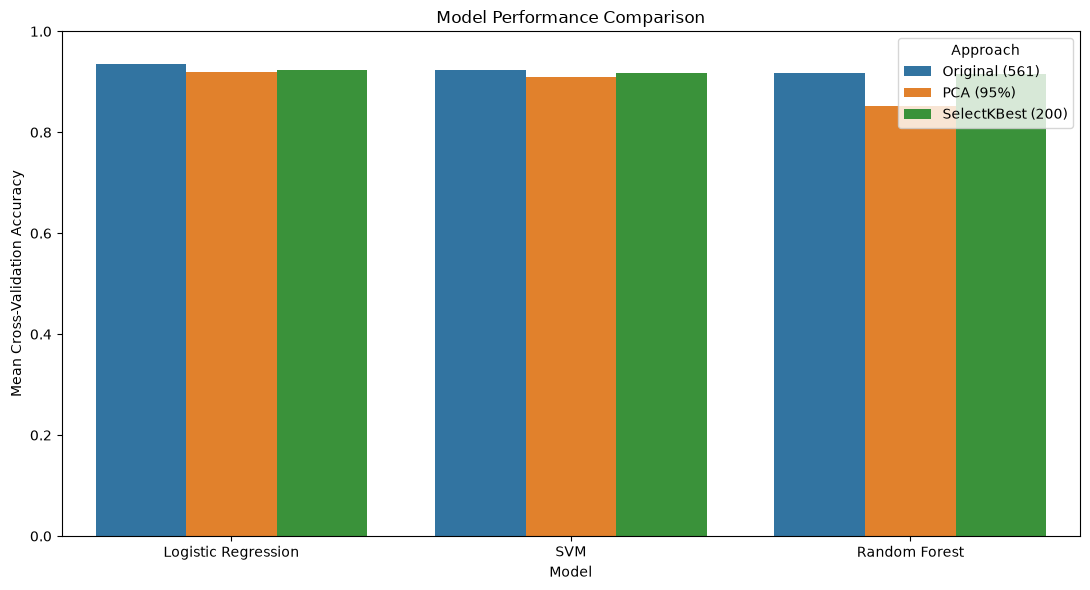

In [24]:
# Compare the main approaches
plot_df = comparison_df[
    (comparison_df["Approach"].isin(["Original", "PCA (95%)"])) |
    (
        (comparison_df["Approach"] == "SelectKBest") &
        (comparison_df["Dimensions"] == 200)
    )
].copy()

plot_df["Approach"] = plot_df["Approach"].replace({
    "Original": "Original (561)",
    "SelectKBest": "SelectKBest (200)"
})

plt.figure(figsize=(11, 6))

sns.barplot(
    data=plot_df,
    x="Model",
    y="Mean Accuracy",
    hue="Approach"
)

plt.title("Model Performance Comparison")
plt.ylabel("Mean Cross-Validation Accuracy")
plt.xlabel("Model")
plt.ylim(0, 1)
plt.legend(title="Approach")
plt.tight_layout()
plt.show()

### 5.1 Overall Model Comparison

Logistic Regression achieved the highest mean accuracy (93.42%) and macro F1-score (93.30%) using all 561 original features.

Applying PCA reduced classification performance across all three models, with Random Forest experiencing the largest decrease in accuracy.

Feature selection with 200 features generally preserved performance more effectively, particularly for Random Forest, whose accuracy decreased by only 0.15 percentage points compared with its baseline.

However, PCA used fewer dimensions than the 200-feature selection approach, making direct comparisons dependent on the desired balance between dimensionality and predictive performance.

Overall, the results suggest that dimensionality reduction can preserve high classification performance, but its effectiveness depends on the method and classification algorithm.

## 6. Final Model Evaluation

Based on the cross-validation results, Logistic Regression using all 561 original features was selected as the final model, achieving the highest mean accuracy and macro F1-score.

We train the selected model on the complete training dataset and evaluate its performance on the independent test set.

We use accuracy, macro F1-score, a classification report, and a confusion matrix to assess the model's ability to recognize the six activities and identify potential classification errors.

In [25]:
# Train the selected model on the full training set
lr_pipeline.fit(X_train, y_train)

# Predict activities on the test set
y_pred = lr_pipeline.predict(X_test)

In [26]:
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    ConfusionMatrixDisplay
)

# Evaluate the final model
test_accuracy = accuracy_score(y_test, y_pred)
test_f1 = f1_score(y_test, y_pred, average="macro")

print(f"Test Accuracy: {test_accuracy:.4f}")
print(f"Test F1-macro: {test_f1:.4f}")

# Detailed performance for each activity
print("\nClassification Report:")
print(classification_report(y_test, y_pred))


Test Accuracy: 0.9545
Test F1-macro: 0.9544

Classification Report:
                    precision    recall  f1-score   support

            LAYING       1.00      0.99      0.99       537
           SITTING       0.97      0.88      0.92       491
          STANDING       0.89      0.97      0.93       532
           WALKING       0.94      0.99      0.97       496
WALKING_DOWNSTAIRS       0.99      0.94      0.96       420
  WALKING_UPSTAIRS       0.96      0.95      0.95       471

          accuracy                           0.95      2947
         macro avg       0.96      0.95      0.95      2947
      weighted avg       0.96      0.95      0.95      2947



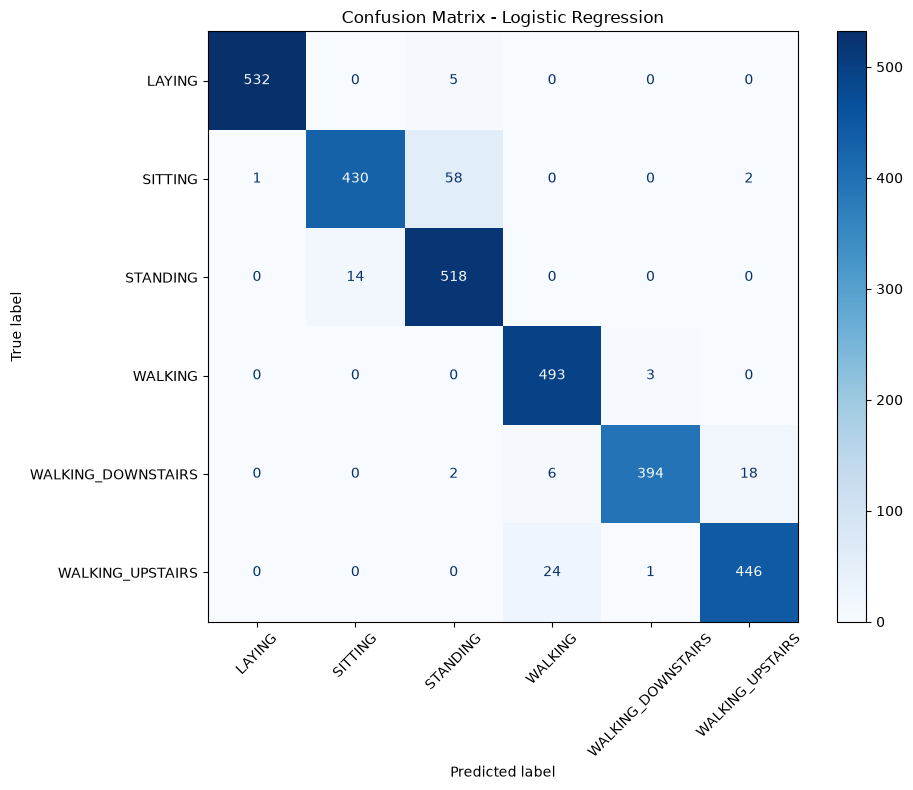

In [27]:
# Plot the confusion matrix
fig, ax = plt.subplots(figsize=(10, 8))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    cmap="Blues",
    values_format="d",
    xticks_rotation=45,
    ax=ax
)

ax.set_title("Confusion Matrix - Logistic Regression")
plt.tight_layout()
plt.show()

In [28]:
# Compare cross-validation and test performance
final_results = pd.DataFrame({
    "Evaluation": ["Cross-validation", "Test Set"],
    "Accuracy": [
        lr_scores["test_accuracy"].mean(),
        test_accuracy
    ],
    "F1-macro": [
        lr_scores["test_f1_macro"].mean(),
        test_f1
    ]
})

display(final_results.round(4))

,Evaluation,Accuracy,F1-macro
0,Cross-validation,0.9345,0.9335
1,Test Set,0.9545,0.9544


### Performance–Dimensionality Trade-off

Although Logistic Regression using all 561 features achieved the highest mean cross-validation accuracy (93.42%), the difference compared with the reduced representations was relatively small.

SelectKBest with 200 features achieved 92.42% accuracy, reducing dimensionality by 64.3% with a decrease of only 1 percentage point.

Similarly, PCA retained at least 95% of the variance using approximately 102 components, achieving 91.94% accuracy.

These results suggest that dimensionality reduction can substantially decrease the number of dimensions while preserving competitive classification performance.

Therefore, the original Logistic Regression model was selected for final evaluation based on its highest mean cross-validation performance. However, the reduced models represent promising alternatives when dimensionality is an important consideration.

## 7. Conclusion

This project investigated the impact of dimensionality reduction and feature selection on Human Activity Recognition using smartphone sensor data.

We compared three machine learning models: Logistic Regression, SVM, and Random Forest, using the original 561 features, Principal Component Analysis (PCA), and feature selection with SelectKBest.

Our experiments showed that dimensionality reduction can substantially decrease the number of dimensions while maintaining relatively high classification performance. However, PCA reduced the accuracy of all three models, with a particularly large decrease observed for Random Forest.

Feature selection with 200 features provided a promising trade-off between dimensionality and predictive performance. Logistic Regression achieved 92.42% cross-validation accuracy, compared with 93.42% using all 561 features. Random Forest also maintained performance close to its baseline, with an accuracy decrease of only 0.15 percentage points.

Logistic Regression using all 561 original features achieved the highest mean cross-validation accuracy of 93.42%. The selected model also demonstrated strong generalization on the independent test set, achieving 95.52% accuracy and a macro F1-score of 95.50%.

Overall, our findings suggest that dimensionality reduction can preserve competitive classification performance with substantially fewer dimensions. However, its effectiveness depends on the reduction method, the number of retained dimensions, and the classification algorithm.

These findings are limited to the dataset and model configurations evaluated in this study. Future work could explore additional feature selection techniques, hyperparameter optimization, and computational efficiency to better understand the trade-off between dimensionality and predictive performance.

## State of the Art and Related Work

Human Activity Recognition (HAR) using smartphone sensors has been widely studied in the machine learning literature.

### Original Benchmark

Anguita et al. (2013) introduced the UCI Human Activity Recognition Using Smartphones dataset and evaluated a multiclass Support Vector Machine (SVM) using Gaussian kernels.

Their approach achieved approximately 96% classification accuracy on the official test set, consisting of 2,947 observations.

The authors also highlighted difficulties in distinguishing certain static activities, particularly SITTING and STANDING.

### Recent Research on Feature Selection

More recently, Gao et al. (2026) investigated feature selection and model interpretability using the same dataset.

Their approach combined Boruta feature selection with Random Forest-based Recursive Feature Elimination (RFE). They evaluated several classifiers, including SVM, Random Forest, and XGBoost.

Using all 561 features, XGBoost achieved 95.55% test accuracy and a macro F1-score of 95.50%.

After reducing the dataset to 100 selected features, test accuracy decreased to 93.89%, illustrating the trade-off between dimensionality reduction and classification performance.

### Comparison with Our Approach

Our project compares three classical machine learning models: Logistic Regression, SVM, and Random Forest. We investigate the effects of two dimensionality reduction approaches: Principal Component Analysis (PCA) and feature selection using SelectKBest.

Logistic Regression using all 561 original features achieved the highest mean cross-validation accuracy of 93.42%. The selected model obtained 95.52% accuracy and a macro F1-score of 95.50% on the official test set.

These results are comparable to those reported in the original benchmark and the recent XGBoost study, although differences in model configurations and evaluation procedures should be considered.

Our experiments also showed that dimensionality reduction can preserve high classification performance. In particular, SelectKBest with 200 features achieved 92.42% cross-validation accuracy with Logistic Regression, reducing dimensionality by 64.3% with an accuracy decrease of only 1 percentage point.

However, the impact of dimensionality reduction varied across models, with PCA causing a larger performance decrease for Random Forest.

Rather than introducing a new classification algorithm, our contribution consists of a systematic experimental comparison of classification performance, dimensionality reduction, and feature selection, using subject-aware cross-validation to assess generalization to unseen individuals.

### References

1. Anguita, D., Ghio, A., Oneto, L., Parra, X., & Reyes-Ortiz, J. L. (2013). *A Public Domain Dataset for Human Activity Recognition Using Smartphones*. ESANN 2013. https://www.esann.org/sites/default/files/proceedings/legacy/es2013-84.pdf

2. Gao, H., Wang, N., Wan, Z., & Qu, R. (2026). *Compact and Explainable Human Activity Recognition with Boruta-RFE Feature Selection and SHAP Interpretation*. Applied Sciences, 16(20), 10046. https://doi.org/10.3390/app162010046